# Tema VI - Algoritmos de Clasificación en Python

## Objetivos de Aprendizaje

Al finalizar este cuaderno serás capaz de:

- Diferenciar Problemas de Clasificación
- Garantizar la Representatividad de las Clases
- Utilizar modelos Lineales basados en Distancia
- Utilizar modelos basados en Árboles y Ensembles
- Utilizar correctamente las Métricas de Evaluación y de Diagnóstico
- Optimizar Hiperparámetros
- Realizar Validación Cruzada
___

## Fundamentos de Clasificación, Muestreo Estratificado y Pipelines

### Objetivos

Al finalizar este apartado serás capaz de:

* Diferenciar problemas de clasificación binaria y multiclase en el aprendizaje supervisado.
* Garantizar la representatividad de las clases mediante la división estratificada (stratify=y).
* Implementar Pipelines de Scikit-Learn para encapsular el preprocesamiento y la estimación, evitando la contaminación de datos (Data Leakage).

### Definición del Problema de Clasificación

A diferencia de la regresión, la clasificación busca predecir una variable respuesta discreta $y \in \{0, 1, \dots, K-1\}$ a partir de una matriz de características $X \in \mathbb{R}^{n \times p}$.
- **Clasificación Binaria:** $y \in \{0, 1\}$. Convencionalmente, la clase $1$ representa el evento o condición de interés (clase positiva) y la clase $0$ representa la ausencia o estado por defecto (clase negativa).
- **Clasificación Multiclase:** $y \in \{0, 1, \dots, K-1\}$ con $K > 2$.

### División de Datos y Muestreo Estratificado

Al dividir el conjunto de datos en entrenamiento (Train) y prueba (Test), una división aleatoria simple puede alterar la proporción original de las clases en cada subconjunto, especialmente si la variable objetivo presenta desbalanceo.

El muestreo estratificado conserva la proporción exacta de las categorías de la variable objetivo tanto en el conjunto de entrenamiento como en el de evaluación:

In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix, fbeta_score, roc_auc_score, precision_recall_curve, auc

In [46]:
# Importamos los datos desde CSV
ruta = r"C:\Users\jorge.crespo.UNEATPDIPAS\Documents\TÉCNICAS DE PROGRAMACIÓN EN IA\EDA\DatosCombinados.csv" # Copiar aquí la ruta al fichero
df = pd.read_csv(ruta, sep=',')

# Definimos la matriz de características y la variable objetivo
X = df.drop(columns=['Churn', 'State', 'Area_Code', 'Phone', 'Day_Charge', 'Eve_Charge', 'Night_Charge', 'Intl_Charge']).reset_index()
y =df['Churn']


# Supongamos X (matriz de características) e y (variable objetivo)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y,       # Conserva la proporción de clases
    random_state=42
)

### Encapsulamiento sin Fuga de Datos mediante Pipeline

El error metodológico más común consiste en calcular parámetros de preprocesamiento (como la media y desviación estándar en el escalado, o la imputación de nulos) utilizando todo el conjunto de datos antes de la división. Esto introduce información del conjunto de prueba en el modelo (Data Leakage).

El objeto Pipeline de Scikit-Learn encadena transformadores y estimadores, asegurando que cualquier transformación aprenda sus parámetros (fit) exclusivamente con los datos de entrenamiento y los aplique (transform) al conjunto de prueba o validación.

In [47]:
# Definición del flujo modular
pipeline_clasificacion = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

# Entrenamiento seguro: fit aprende los parámetros del escalador y del modelo solo en Train
pipeline_clasificacion.fit(X_train, y_train)

# Evaluación: aplica transform a Test usando los parámetros aprendidos en Train
y_pred = pipeline_clasificacion.predict(X_test)

score = pipeline_clasificacion.score(X_test, y_test)
params = pipeline_clasificacion.get_params(deep=True)

print(score)

0.8605697151424287


### Ideas Clave

- Definición clara de la clase positiva: Asignar siempre la etiqueta $1$ al evento o condición principal objeto del estudio para garantizar la correcta interpretación de métricas posteriores.
- Innegociabilidad de la estratificación: Omitir stratify=y en conjuntos de datos pequeños o desbalanceados distorsiona las estimaciones de rendimiento del modelo.
- Pipeline como unidad de trabajo: Un Pipeline permite evaluar y desplegar modelos de forma robusta, segura y reproducible, garantizando un flujo de trabajo profesional.
___

## Modelos Lineales y Basados en Distancia

### Objetivos

Al finalizar este apartado serás capaz de:

* Comprender el funcionamiento matemático de la Regresión Logística y la interpretación probabilística de sus coeficientes.
* Analizar el algoritmo de $K$-Vecinos Más Cercanos ($K$-NN), su dependencia de las métricas de distancia y su sensibilidad a las escalas.
* Aplicar regularización ($L_1/L_2$) en modelos lineales para prevenir el sobreajuste (overfitting).

### Regresión Logística

A pesar de su nombre, la Regresión Logística es un algoritmo de clasificación. Modela la probabilidad de que una observación pertenezca a la clase positiva ($y=1$) mediante la función sigmoide (o logística), la cual mapea cualquier valor real al intervalo $(0, 1)$:

$$P(y=1\vert{}X) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{donde } z = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$$



              1.0    ┤                      ┌───────
                     │                   ┌──┘
       P(y=1)        │                 ┌─┘
              0.5    ┤───────────────┬─┘
                     │             ┌─┘
              0.0    |─────────────┴───────────────
                     -∞               0              +∞
                               z = Xβ

**Interpretación de Coeficientes (Odds Ratio)**

El cociente de probabilidades (Odds) se define como la razón entre la probabilidad de que ocurra el evento y la probabilidad de que no ocurra:

$$\text{Odds} = \frac{P(y=1)}{1 - P(y=1)} = e^{\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p}$$

- $\beta_j > 0$: Un incremento en $x_j$ aumenta la probabilidad de la clase positiva ($e^{\beta_j} > 1$).
- $\beta_j < 0$: Un incremento en $x_j$ disminuye la probabilidad de la clase positiva ($e^{\beta_j} < 1$).



In [48]:
# Extraemos los coeficientes del modelo
coeficientes = pipeline_clasificacion.named_steps['classifier'].coef_[0]
odds_ratios = np.exp(coeficientes)

# Creamos un DataFrame con coeficientes para ppoderlos visualizar fácilmente
df_coef = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente_Beta': coeficientes,
    'Odds_Ratio': odds_ratios
}).sort_values(by='Odds_Ratio', ascending=False)

print(df_coef)

          Variable  Coeficiente_Beta  Odds_Ratio
6   CustServ_Calls          0.769818    2.159372
12       Intl_Plan          0.648518    1.912704
1    VMail_Message          0.561983    1.754148
14          Charge          0.408967    1.505262
2         Day_Mins          0.318099    1.374513
..             ...               ...         ...
54              RI         -0.132891    0.875561
60              VA         -0.167124    0.846095
10      Intl_Calls         -0.205284    0.814416
26              HI         -0.233904    0.791438
13      VMail_Plan         -0.993582    0.370248

[69 rows x 3 columns]


### $K$-Vecinos Más Cercanos ($K$-NN / $K$-Nearest Neighbors)

$K$-NN es un algoritmo no paramétrico y basado en instancias (lazy learning). No entrena un modelo explícito con parámetros $\beta$, sino que almacena el conjunto de datos de entrenamiento.

Para clasificar una nueva observación:
1. Calcula la distancia (ej. Euclídea o Manhattan) entre la nueva observación y todos los puntos de entrenamiento.
2. Identifica los $k$ vecinos más cercanos.
3. Asigna la clase mediante voto mayoritario (o promedio ponderado por la distancia inversa).

$$\text{Distancia Euclídea: } d(\mathbf{p}, \mathbf{q}) = \sqrt{\sum_{i=1}^p (p_i - q_i)^2}$$

In [49]:
# Definición del clasificador K-NN
modelo_knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
modelo_knn.fit(X_train, y_train)

score_knn = modelo_knn.score(X_test, y_test)
print(score_knn)

0.8665667166416792


**Comparación Técnica**

|Criterio|Regresión Logística|K-Vecinos Más Cercanos (K-NN)|
|:--------:|:--------------------:|:----------------------------:|
|Tipo de modelo|Paramétrico (asume frontera lineal)|No paramétrico (fronteras complejas/no lineales)|
|Interpretabilidad|Alta (coeficientes e Odds Ratios)|Baja/Media (depende de la inspección de vecinos)|
|Sensibilidad al escalado|Media (afecta si hay regularización)|Extrema (obligatorio escalar X)|
|Costo computacional|Rápido en entrenamiento y predicción|Lento en predicción con grandes volúmenes de datos|

### Regularización en Modelos Lineales

La regularización es una técnica que añade una penalización por complejidad a la función de pérdida (loss function) que el algoritmo busca minimizar durante el entrenamiento.
Su objetivo principal es prevenir el sobreajuste (overfitting), evitando que el modelo ajuste coeficientes ($\beta$) excesivamente grandes para memorizar el ruido de los datos de entrenamiento.

$$\text{Función de Pérdida Total} = \text{Error de Predicción (Loss)} + \lambda \times \text{Penalización}(\boldsymbol{\beta})$$

Donde 
$\lambda \ge 0$ es el hiperparámetro que controla la fuerza de la regularización:
- Si $\lambda = 0$, el modelo no tiene penalización (coincide con la estimación estándar).
- Cuanto mayor es $\lambda$, más se fuerza a los coeficientes a reducir su tamaño.

**Tipos Principales de Regularización**

1. L1 o Lasso (Norma $L_1$):
    * Fórmula de penalización: $\lambda \sum_{j=1}^p \vert{}\beta_j\vert{}$
    * Efecto: Es capaz de reducir los coeficientes de las variables menos relevantes exactamente a cero.
    * Uso principal: Funciona como un mecanismo implícito de selección de características (Feature Selection), eliminando variables ruidosas o redundantes.
    
2. L2 o Ridge (Norma $L_2$):
    * Fórmula de penalización: $\lambda \sum_{j=1}^p \beta_j^2$
    * Efecto: Contrae (shrinks) todos los coeficientes hacia cero de forma suave, pero nunca los hace exactamente cero.
    * Uso principal: Es ideal cuando existe multicolinealidad (variables explicativas muy correlacionadas entre sí) o cuando queremos preservar todas las características reduciendo la varianza global del modelo.
    
3. ElasticNet (Combinación L1 + L2):
    * Combina ambas normas mediante un parámetro de mezcla ($\alpha$). Aprovecha la selección de características de L1 y la estabilidad ante colinealidad de L2.

**La Convención de Scikit-Learn:** 

El Parámetro CEn las implementaciones de Scikit-Learn (como LogisticRegression o LinearSVC), en lugar de utilizar directamente $\lambda$, se utiliza el parámetro $C$, definido como el inverso de la fuerza de regularización:

$$C = \frac{1}{\lambda}$$

- C grande (ej. C=100.0): Regularización débil ($\lambda \approx 0$). El modelo prioriza ajustar al máximo los datos de entrenamiento (riesgo de overfitting).
- C pequeño (ej. C=0.01): Regularización fuerte ($\lambda$ alto). El modelo simplifica fuertemente los coeficientes (riesgo de underfitting).
- penalty='l2' (Por defecto): Aplica regularización Ridge.

In [50]:
# Definición del flujo modular
pipeline_clasificacion_l2 = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(C=1, solver='liblinear', random_state=42)) #Variando el valor de C y el solver obtenemos resultados diferentes
])

# Modelo con Regularización
pipeline_clasificacion_l2.fit(X_train, y_train)

# Extraemos los coeficientes del modelo
coeficientes_l2 = pipeline_clasificacion_l2.named_steps['classifier'].coef_[0]
odds_ratios_l2 = np.exp(coeficientes_l2)

# Creamos un DataFrame con coeficientes para ppoderlos visualizar fácilmente
df_coef_l2 = pd.DataFrame({
    'Variable': X_train.columns,
    'Coeficiente_Beta': coeficientes_l2,
    'Odds_Ratio': odds_ratios_l2
}).sort_values(by='Odds_Ratio', ascending=False)

print(df_coef_l2)

          Variable  Coeficiente_Beta  Odds_Ratio
6   CustServ_Calls          0.764114    2.147091
12       Intl_Plan          0.644811    1.905627
1    VMail_Message          0.555107    1.742127
14          Charge          0.406010    1.500818
2         Day_Mins          0.314916    1.370144
..             ...               ...         ...
54              RI         -0.131279    0.876973
60              VA         -0.165501    0.847469
10      Intl_Calls         -0.203886    0.815555
26              HI         -0.229597    0.794854
13      VMail_Plan         -0.982268    0.374461

[69 rows x 3 columns]


## Modelos Basados en Árboles de Decisión y Ensembles

### Objetivos

Al finalizar este apartado serás capaz de:

* Comprender la lógica de partición recursiva y las métricas de pureza en Árboles de Decisión.
* Analizar los métodos de agregación por ensamble (Ensemble Learning): Bagging y Boosting.
* Implementar y comparar Random Forest y algoritmos de Gradient Boosting (XGBoost / LightGBM).
* Interpretar la importancia de características (Feature Importance) e hiperparámetros de poda.

### Árboles de Decisión (Decision Trees)

Los árboles de decisión segmentan el espacio de características mediante particiones binarias recursivas y perpendiculares a los ejes.

**Criterios de División (Pureza)**

Para determinar la mejor variable y punto de corte, el algoritmo evalúa la reducción en la impureza de los nodos hijos:

- **Índice Gini:** Mide la frecuencia con la que un elemento elegido al azar sería clasificado incorrectamente.

$$Gini = 1 - \sum_{i=1}^{K} p_i^2$$

- **Entropía (Ganancia de Información):** Mide la incertidumbre o desorden del nodo.

$$Entropía = -\sum_{i=1}^{K} p_i \log_2(p_i)$$

0.9580209895052474


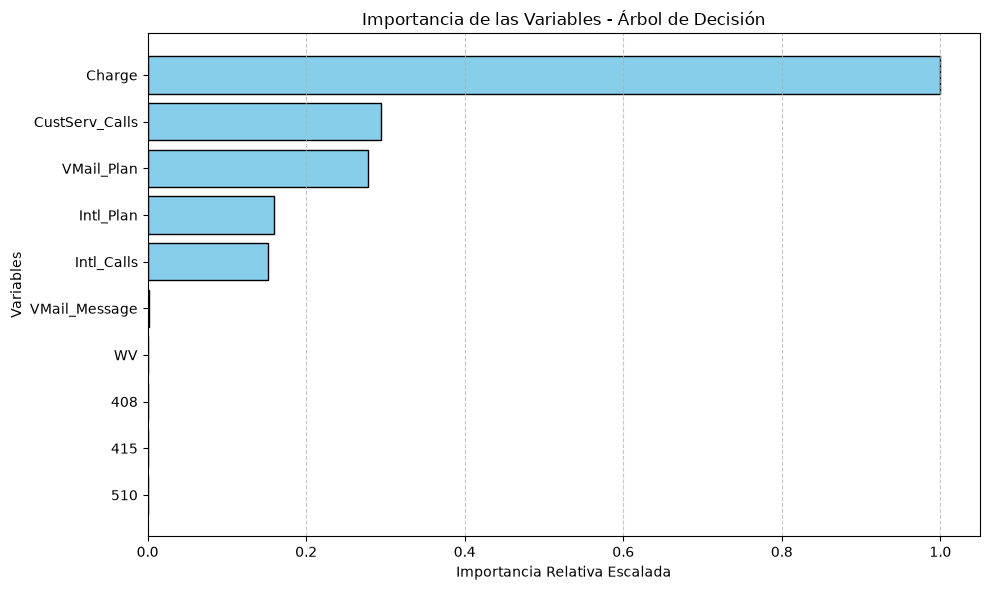

In [77]:
# Modelo con poda explícita para evitar sobreajuste
modelo_arbol = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,              # Profundidad máxima del árbol
    min_samples_split=10,     # Mínimo de muestras para dividir un nodo
    min_samples_leaf=5,       # Mínimo de muestras en nodo hoja
    random_state=42
)
modelo_arbol.fit(X_train, y_train)

score_tree = modelo_arbol.score(X_test, y_test)
print(score_tree)

# Importancia relativa de las variables
importancias_tree = modelo_arbol.feature_importances_
importances_tree = importancias_tree / np.max(importancias_tree)
indices = np.argsort(importances_tree)[::-1]

# Selección de las N variables más importantes
top_n = 10
indices_top = indices[:top_n]
indices_predictores = X.columns.values

# Graficamos el resultado
plt.figure(figsize=(10,6))
plt.barh(range(top_n), importances_tree[indices_top][::-1], color='skyblue', edgecolor='black')
plt.yticks(range(top_n), indices_predictores[indices_top][::-1])

plt.xlabel('Importancia Relativa Escalada')
plt.ylabel('Variables')
plt.title('Importancia de las Variables - Árbol de Decisión')
plt.grid(axis='x', linestyle='--', alpha=0.7) # Añade líneas guía de fondo
plt.tight_layout()
plt.show()


### Random Forest (Bagging)

Un árbol individual tiende a sufrir de varianza elevada (overfitting). Random Forest mitiga esto combinando múltiples árboles mediante Bagging (Bootstrap Aggregating) y aleatorización de características.

- Bootstrap: Entrena cada árbol con un subconjunto aleatorio de observaciones obtenido con reemplazo.
- Subespacio aleatorio: En cada división de cada árbol, evalúa solo un subconjunto aleatorio de $m = \sqrt{p}$ características.
- Agregación: Combina las predicciones individuales mediante voto mayoritario (clasificación) o promediado de probabilidades.

0.9115442278860569


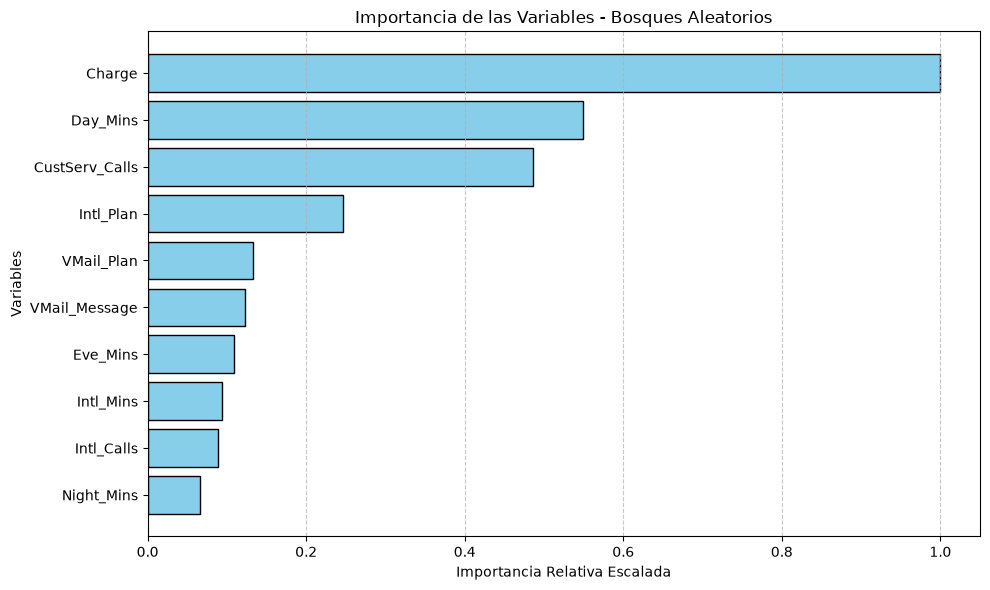

In [79]:
modelo_rf = RandomForestClassifier(
    n_estimators=100,         # Número de árboles en el bosque
    max_features="sqrt",      # Características evaluadas por división
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

score_rf = modelo_rf.score(X_test, y_test)
print(score_rf)

# Importancia relativa de las variables
importancias_rf = modelo_rf.feature_importances_
importances_rf = importancias_rf / np.max(importancias_rf)
indices = np.argsort(importances_rf)[::-1]

# Selección de las N variables más importantes
top_n = 10
indices_top = indices[:top_n]
indices_predictores = X.columns.values

# Graficamos el resultado
plt.figure(figsize=(10,6))
plt.barh(range(top_n), importances_rf[indices_top][::-1], color='skyblue', edgecolor='black')
plt.yticks(range(top_n), indices_predictores[indices_top][::-1])

plt.xlabel('Importancia Relativa Escalada')
plt.ylabel('Variables')
plt.title('Importancia de las Variables - Bosques Aleatorios')
plt.grid(axis='x', linestyle='--', alpha=0.7) # Añade líneas guía de fondo
plt.tight_layout()
plt.show()


### Gradient Boosting (Boosting)

A diferencia del enfoque en paralelo de Random Forest, los algoritmos de Gradient Boosting construyen árboles de forma secuencial. Cada nuevo árbol se entrena para corregir los errores (residuos o gradientes de la función de pérdida) cometidos por la combinación de los árboles anteriores.

$$\hat{y}_i^{(m)} = \hat{y}_i^{(m-1)} + \eta f_m(x_i)$$

Donde $\eta$ representa la tasa de aprendizaje (learning rate), que controla la contribución de cada nuevo modelo.

0.9685157421289355


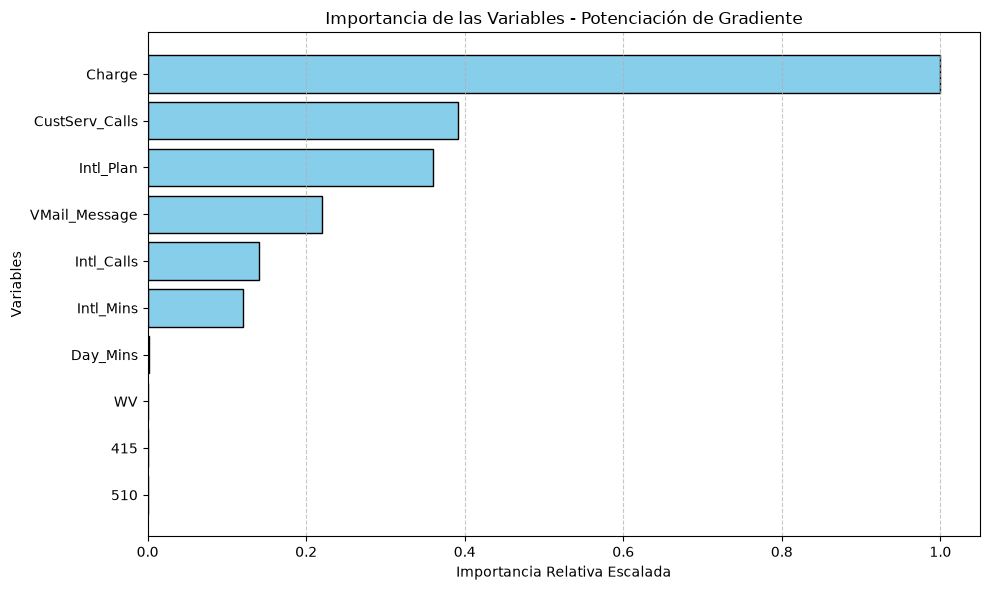

In [83]:
# HistGradientBoosting (Nativo en sklearn, optimizado para alto rendimiento)
modelo_gb = HistGradientBoostingClassifier(
    learning_rate=0.05,       # Tasa de aprendizaje
    max_iter=100,             # Número equivalente de estimadores
    max_depth=5,
    random_state=42
)
modelo_gb.fit(X_train, y_train)

score_gb = modelo_gb.score(X_test, y_test)
print(score_gb)

# Importancia relativa de las variables

resultado = permutation_importance(
    modelo_gb, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

importancias_gb = resultado.importances_mean
importances_gb = importancias_gb / np.max(importancias_gb)
indices = np.argsort(importances_gb)[::-1]

# Selección de las N variables más importantes
top_n = 10
indices_top = indices[:top_n]
indices_predictores = X.columns.values

# Graficamos el resultado
plt.figure(figsize=(10,6))
plt.barh(range(top_n), importances_gb[indices_top][::-1], color='skyblue', edgecolor='black')
plt.yticks(range(top_n), indices_predictores[indices_top][::-1])

plt.xlabel('Importancia Relativa Escalada')
plt.ylabel('Variables')
plt.title('Importancia de las Variables - Potenciación de Gradiente')
plt.grid(axis='x', linestyle='--', alpha=0.7) # Añade líneas guía de fondo
plt.tight_layout()
plt.show()

### Cuadro Comparativo de Familias de Árboles

|Criterio|Árbol Individual|Random Forest (Bagging)|Gradient Boosting (Boosting)|
|--------|----------------|-----------------------|----------------------------|
|Construcción|Único árbol|Múltiples árboles en paralelo|Múltiples árboles en secuencia|
|Riesgo principal|Sobreajuste (Alta varianza)|Ligeramente propenso si N es bajo|Sobreajuste si η es alto o N excesivo|
|Escalado de datos|No requiere|No requiere|No requiere|
|Sensibilidad a ruido|Alta|Baja/Moderada|Alta (puede memorizar ruido si no se poda)|

### ideas Clave

- Invariancia a transformaciones monótonas: Los modelos basados en árboles no requieren escalado (StandardScaler, MinMaxScaler) ni transformaciones logarítmicas de las características continuas.
- Poda explícita en árboles individuales: Sin restricciones (max_depth=None), un árbol de decisión memorizará el conjunto de entrenamiento alcanzando un $100\%$ de Accuracy en Train, pero generalizará muy mal en Test.
- Efecto de la tasa de aprendizaje ($\eta$): En Gradient Boosting, tasas de aprendizaje más bajas conducen a un mejor rendimiento de generalización, pero requieren un mayor número de estimadores/iteraciones.
___

## Métricas de Evaluación y Diagnóstico de Modelos

### Onjetivos

Al finalizar este apartado serás capaz de:

* Estudiar la Matriz de Confusión como base para derivar las métricas de rendimiento.
* Distinguir cuándo utilizar Accuracy, Precision, Recall (Sensibilidad), $F_1$-Score y $F_\beta$-Score.
* Evaluar el comportamiento global de los clasificadores mediante Curvas ROC (ROC-AUC) y Curvas Precision-Recall (PR-AUC).

### La matriz de Confusión

La matriz de confusión organiza las predicciones frente a los valores reales en cuatro cuadrantes fundamentales:

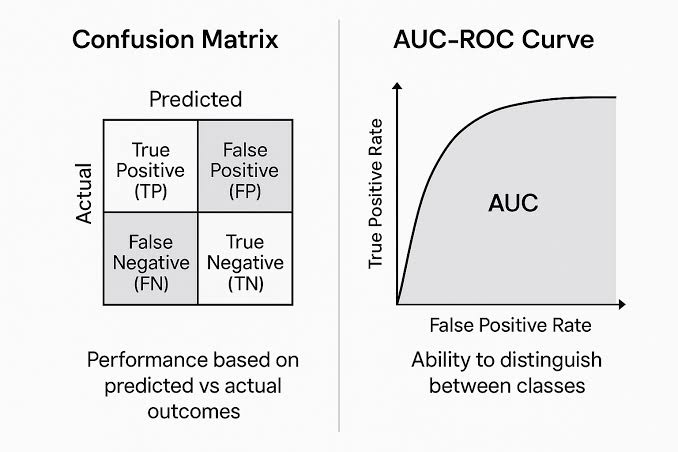

||Predicho: Clase 0|Predicho: Clase 1|
|---------|--------|-----------------|
|**Real: Clase 0**|Verdadero Negativo (VN)|Falso Positivo (FP) — Error Tipo I|
|**Real: Clase 1**|Falso Negativo (FN) — Error Tipo II|Verdadero Positivo (VP)|

### Métricas Derivadas y Selección según el Contexto

$$\text{Accuracy} = \frac{VP + VN}{VP + VN + FP + FN}$$

$$\text{Precision} = \frac{VP}{VP + FP}$$

$$\text{Recall (Sensibilidad)} = \frac{VP}{VP + FN}$$

$$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

$$F_\beta = (1 + \beta^2) \times \frac{\text{Precision} \times \text{Recall}}{(\beta^2 \times \text{Precision}) + \text{Recall}}$$

### Criterio de Selección de Métricas

* Exactitud (Accuracy): Mide la proporción global de aciertos. Es adecuada únicamente con clases balanceadas. Con clases desbalanceadas, ofrece una falsa sensación de rendimiento.
* Precisión (Precision): Cuántos de los elementos clasificados como positivos son realmente positivos. Se prioriza cuando el coste de un Falso Positivo es elevado (ej. detección de spam, donde bloquear un correo importante perjudica al usuario).
* Sensibilidad (Recall): Cuántos de los elementos reales de la clase positiva fueron detectados. Se prioriza cuando el coste de un Falso Negativo es crítico (ej. detección de cáncer o transacciones fraudulentas).
* Puntuación $F_1$ / $F_\beta$: Media armónica entre Precision y Recall.
    - $F_1$ equilibra ambas métricas por igual.
    - $F_{\beta=2}$ da el doble de importancia al Recall sobre la Precision.
    - $F_{\beta=0.5}$ prioriza la Precision sobre el Recall.

In [98]:
#Definimos un diccionario con los distintos algoritmos entrenados

algoritmos = {
    'Regresión Logística': pipeline_clasificacion,
    'KNN': modelo_knn,
    'Regresión Logística con Regularización L2': pipeline_clasificacion_l2,
    'Árbol de Decisión': modelo_arbol,
    'Random Forest': modelo_rf,
    'Gradient Boost': modelo_gb 
}

# Definimos una función para imprimir los reportes
def reporte_clasificación(pred):
    # Generación del informe completo de métricas
    print("--- Matriz de Confusión ---")
    print(confusion_matrix(y_test, pred))

    print("\n--- Reporte de Clasificación ---")
    print(classification_report(y_test, pred, target_names=["Clase 0", "Clase 1"]))

    # Cálculo explícito de F-Score según betas
    betas = [1, 2, 0.5]
    
    for b in betas:
        f_beta = fbeta_score(y_test, pred, beta=b)
        print("F"+str(b)+"-Score: " + f"{f_beta:.4f}")

# Iteramos entre todos los algoritmos para hacer las predicciones de forma dinámica e imprimir el reporte
for nombre, algoritmo in algoritmos.items():
    print(f"\nEvaluando {nombre}...")
    predicciones = algoritmo.predict(X_test)
    reporte_clasificación(predicciones)



Evaluando Regresión Logística...
--- Matriz de Confusión ---
[[546  24]
 [ 69  28]]

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

     Clase 0       0.89      0.96      0.92       570
     Clase 1       0.54      0.29      0.38        97

    accuracy                           0.86       667
   macro avg       0.71      0.62      0.65       667
weighted avg       0.84      0.86      0.84       667

F1-Score:0.3758
F2-Score:0.3182
F0.5-Score:0.4590

Evaluando KNN...
--- Matriz de Confusión ---
[[561   9]
 [ 80  17]]

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

     Clase 0       0.88      0.98      0.93       570
     Clase 1       0.65      0.18      0.28        97

    accuracy                           0.87       667
   macro avg       0.76      0.58      0.60       667
weighted avg       0.84      0.87      0.83       667

F1-Score:0.2764
F2-Score:0.2053
F0.5-Score:0.4229

Evaluando Regresión Log

### Diagnóstico probabilístico: Curvas ROC y Precision-Recall

Dado que la mayoría de clasificadores estiman una probabilidad $P(y=1\vert{}X)$, la decisión final depende del umbral de corte (decision threshold, por defecto $0.5$).

**Curva ROC y ROC-AUC**

Representa la Tasa de Verdaderos Positivos ($TVP = Recall$) frente a la Tasa de Falsos Positivos ($TFP = \frac{FP}{FP + VN}$) a lo largo de todos los umbrales posibles.

* ROC-AUC = 0.5: Clasificador aleatorio sin capacidad discriminatoria.
* ROC-AUC = 1.0: Clasificador perfecto.

**Curva Precision-Recall (PR-AUC)**

Grafica la Precision frente al Recall para diferentes umbrales. Es más informativa que la curva ROC en problemas con desbalanceo severo de clases, ya que la Tasa de Falsos Positivos ($TFP$) en la curva ROC se atenúa al tener un número muy elevado de Verdaderos Negativos ($VN$).

In [100]:
# Iteramos entre todos los algoritmos para hacer las predicciones de forma dinámica e imprimir el reporte
for nombre, algoritmo in algoritmos.items():
    print(f"\nEvaluando {nombre}...")
    
    # Obtención de probabilidades para la clase positiva (1)
    y_probs = algoritmo.predict_proba(X_test)[:, 1]
    
    # ROC-AUC
    score_roc = roc_auc_score(y_test, y_probs)

    # PR-AUC
    precisiones, recalls, umbrales = precision_recall_curve(y_test, y_probs)
    score_pr_auc = auc(recalls, precisiones)

    print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")


Evaluando Regresión Logística...
ROC-AUC: 0.8012 | PR-AUC: 0.4337

Evaluando KNN...
ROC-AUC: 0.6578 | PR-AUC: 0.3401

Evaluando Regresión Logística con Regularización L2...
ROC-AUC: 0.8015 | PR-AUC: 0.4342

Evaluando Árbol de Decisión...
ROC-AUC: 0.9060 | PR-AUC: 0.8684

Evaluando Random Forest...
ROC-AUC: 0.9046 | PR-AUC: 0.8663

Evaluando Gradient Boost...
ROC-AUC: 0.8973 | PR-AUC: 0.8633


### Ideas Clave

- Falta de representatividad del Accuracy: Un clasificador que prediga siempre la clase mayoritaria en un conjunto con $95\%$ de ceros tendrá un $95\%$ de Accuracy, pero será inútil en la práctica.
- Rivalidad entre Precision y Recall: Aumentar el Recall reduciendo el umbral de decisión incrementa inevitablemente los Falsos Positivos, reduciendo la Precision.
- Uso de PR-AUC con desbalanceo: La curva ROC puede resultar demasiado optimista cuando la clase negativa es dominante; la curva Precision-Recall refleja con mayor fidelidad las variaciones en los Falsos Positivos.
___

## Optimización de Hiperparámetros, Validación Cruzada y Threshold Tuning

### Objetivos

Al finalizar este apartado será capaz de:

* Evaluar la capacidad de generalización mediante Validación Cruzada Estratificada (Stratified K-Fold).
* Optimizar hiperparámetros de manera sistemática utilizando GridSearchCV y RandomizedSearchCV.
* Configurar la búsqueda orientada a la métrica de negocio/dominio específica (scoring).
* Ajustar el umbral de decisión (Threshold Tuning) para optimizar el balance entre Falsos Positivos y Falsos Negativos.

### Validación Cruzada Estratificada (Stratified K-Fold Cross-Validation)

Efectuar una única división Train/Test puede producir estimaciones sesgadas dependiendo de la partición concreta. La Validación Cruzada de $K$ Pliegues Estratificada divide los datos de entrenamiento en $K$ subconjuntos iguales, manteniendo la proporción original de las clases en cada uno.


|Iteración|Pliegue 1|Pliegue 2|Pliegue 3|Pliegue 4|Pliegue 5|
|---------|---------|---------|---------|---------|---------|
|Iter 1|[ Test ]|[ Train ]|[ Train ]|[ Train ]|[ Train ]|
|Iter 2|[ Train ]|[ Test ]|[ Train ]|[ Train ]|[ Train ]|
|Iter 3|[ Train ]|[ Train ]|[ Test ]|[ Train ]|[ Train ]|
|Iter 4|[ Train ]|[ Train ]|[ Train ]|[ Test ]|[ Train ]|
|Iter 5|[ Train ]|[ Train ]|[ Train ]|[ Train ]|[ Test ]|

### Búsqueda Sistemática de Hiperparámetros

Mientras que los parámetros se aprenden durante el entrenamiento (ej. coeficientes $\beta$), los hiperparámetros son configuraciones externas al algoritmo (ej. max_depth, C, n_neighbors).

**Estrategias de Búsqueda**

* **GridSearchCV:** Evalúa exhaustivamente todas las combinaciones posibles dentro de un emparrillado definido. Es garantizado pero exhaustivo computacionalmente.

* **RandomizedSearchCV:** Muestrea un número fijo de combinaciones aleatorias (n_iter) dentro de distribuciones dadas. Es más eficiente en espacios de búsqueda amplios.

In [103]:
# Ejemplo de Optimización de Hiperparámetros para un Random Forest

# Definición del Pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(random_state=42))
])

# Espacio de hiperparámetros (sintaxis: nombrepaso__nombreparametro)
param_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [4, 6, 8, None],
    "classifier__min_samples_split": [2, 5, 10]
}

# Validación Cruzada Estratificada
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Búsqueda exhaustiva optimizando por la métrica de interés (ej. recall, f2, roc_auc)
grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="roc_auc",       # O 'recall', 'f1', 'f2' según el dominio
    cv=cv_estratificado,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Mejor combinación: {grid_search.best_params_}")
print(f"Mejor puntuación de CV: {grid_search.best_score_:.4f}")

Mejor combinación: {'classifier__max_depth': 8, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Mejor puntuación de CV: 0.9252


### Ajuste del Umbral de Decisión (Threshold Tuning)

Por defecto, los estimadores aplican el método .predict() clasificando como clase positive ($1$) cualquier probabilidad $P(y=1\vert{}X) \ge 0.5$. En escenarios donde los costes de cometer un Falso Negativo o un Falso Positivo son asimétricos, este umbral por defecto resulta subóptimo.

In [113]:
# Obtener las probabilidades predichas del mejor modelo
mejor_modelo = grid_search.best_estimator_
y_probs = mejor_modelo.predict_proba(X_test)[:, 1]

# Ajustar manualmente el umbral de decisión
umbral_personalizado = 0.3  # Al bajar el umbral, se incrementa el Recall

# Generar nuevas predicciones basadas en el umbral ajustado
y_pred_ajustado = (y_probs >= umbral_personalizado).astype(int)

# ROC-AUC
score_roc = roc_auc_score(y_test, y_probs)

# PR-AUC
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_probs)
score_pr_auc = auc(recalls, precisiones)

print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")


# ROC-AUC
score_roc_ad = roc_auc_score(y_test, y_pred_ajustado)

# PR-AUC
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_pred_ajustado)
score_pr_auc = auc(recalls, precisiones)

print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")



ROC-AUC: 0.9096 | PR-AUC: 0.8817
ROC-AUC: 0.9096 | PR-AUC: 0.9117


### Ideas Clave

- Inclusión del Pipeline en el Grid Search: Al evaluar el Pipeline completo dentro de GridSearchCV, se asegura que las transformaciones (como el escalado o la imputación) se calculen exclusivamente dentro de los pliegues de entrenamiento de cada iteración.
- Selección explícita del parámetro scoring: Omitir el parámetro scoring en la búsqueda provocará que GridSearchCV utilice la métrica por defecto del estimador (generalmente Accuracy), lo cual es metodológicamente incorrecto en problemas desbalanceados o de alto riesgo.
- Post-procesamiento mediante el umbral: Modificar el umbral de corte permite adaptar un mismo modelo probabilístico a diferentes políticas operativas o de negocio sin necesidad de reentrenar la arquitectura.
___